# Evaluator: Organic Experiential Learning (NK + SARSA)

This notebook evaluates the **figure-oriented** output from `Organic_experiential_learning.py` without AI assistance. The focal parameter is **cumulative learning steps** (SARSA updates). Figures show subsequent evaluation performance and internal-knowledge outcomes, averaged across NK complexity or separately by $K$.

**Inputs:** `organic_learning_settings` and the individual `organic_learning_steps_{steps}_{measure}_across_K` pickle files, including `evaluation_best_fitness_across_time_across_K`. No regression-oriented CSV files are needed. The notebook does **not** rerun the simulations or modify `Landscape.py` or `Individual.py`.

**Interpretation:** Training accumulates internal knowledge; evaluation uses a more exploitative softmax policy without Q-table updates. Performance is measured during a fixed-budget evaluation search, not time to a designated goal.

*Preview note:* Saved figures, if present, were produced using a **small verification run** ($N=5$, $K=0,2$, two NK landscapes and two individuals per landscape). They are for code validation, not substantive inference. Re-execute against your own results directory.

## 1. Configuration and figure style

Figure formatting follows your original visibility-extent evaluator: bold axis labels, black outlined markers for pooled plots, Morandi colors by $K$, subtle grids, and transparent PNG exports at 300 dpi.

Learning budgets often span orders of magnitude; the default **symmetric-log** horizontal axis retains the zero-learning condition. Set `learning_axis = 'linear'` for linear spacing.

Set `result_folder` to the folder defined as `output_dir` in the running script, or provide `ORGANIC_RESULTS_DIR`. The notebook reads $N$, $K$ values, and the learning checkpoints directly from the saved settings file.

In [1]:
from pathlib import Path
import os
import pickle
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Same palette and styling as the supplied Evaluator.ipynb.
legend_properties = {'weight': 'bold'}
nus_blue = '#003D7C'
nus_orange = '#EF7C00'
morandi_blue = '#046586'
morandi_green = '#28A9A1'
morandi_yellow = '#C9A77C'
morandi_orange = '#F4A016'
morandi_pink = '#F6BBC6'
morandi_red = '#E71F19'
morandi_purple = '#B08BEB'
shallow_grey = '#D3D4D3'

K_colors = [morandi_blue, morandi_orange, morandi_green, morandi_purple,
            morandi_red, morandi_yellow, '#555555', '#B75F91']


def format_axis(ax):
    """Match the original evaluator's figure formatting."""
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
        spine.set_color('black')
    ax.grid(alpha=0.5)
    ax.tick_params(axis='both', labelsize=11)
    return ax


def format_learning_axis(ax):
    """Show the actual SARSA update counts, including zero."""
    if learning_axis == 'symlog':
        positives = [step for step in learning_steps_list if step > 0]
        linthresh = min(positives) if positives else 1
        ax.set_xscale('symlog', linthresh=linthresh)
    elif learning_axis != 'linear':
        raise ValueError("learning_axis must be 'symlog' or 'linear'.")
    ax.set_xticks(learning_steps_list)
    ax.set_xticklabels([f'{step:,}' for step in learning_steps_list],
                       rotation=25 if len(learning_steps_list) > 6 else 0,
                       ha='right' if len(learning_steps_list) > 6 else 'center')
    ax.set_xlabel('Cumulative learning steps', fontweight='bold', fontsize=12)
    return ax


def finish_figure(fig, filename):
    fig.tight_layout()
    if save_figures:
        fig.savefig(figure_folder / filename, dpi=300,
                    bbox_inches='tight', transparent=True)
    plt.show()

In [2]:
# =========================
# Experiment configuration — Organic_experiential_learning.py
# =========================
# Optionally set a path explicitly, or set the ORGANIC_RESULTS_DIR environment variable.
result_folder = os.environ.get('ORGANIC_RESULTS_DIR')  # e.g., '/Users/me/results/Organic_experiential_learning_results'

save_figures = True
strict_loading = True            # Fail if any required saved pickle is missing.
learning_axis = 'symlog'         # 'symlog' or 'linear'.

candidate_folders = [Path.cwd() / 'Organic_experiential_learning_results',
                     Path.cwd(), Path.cwd() / 'Results', Path.cwd() / 'results',
                     Path.cwd() / 'output', Path.cwd() / 'data']

if result_folder is None:
    result_folder = next((folder for folder in candidate_folders
                          if (folder / 'organic_learning_settings').is_file()), None)
if result_folder is None:
    raise FileNotFoundError(
        'Could not find organic_learning_settings. Set result_folder to '
        'output_dir in Organic_experiential_learning.py, or set ORGANIC_RESULTS_DIR.')

result_folder = Path(result_folder).expanduser().resolve()
settings_file = result_folder / 'organic_learning_settings'
if not settings_file.is_file():
    raise FileNotFoundError(f'Missing experiment settings: {settings_file}')

figure_folder = result_folder / 'organic_learning_figures'
if save_figures:
    figure_folder.mkdir(parents=True, exist_ok=True)

print('Result folder:', result_folder)
print('Figure folder:', figure_folder)
print('Save PNG figures:', save_figures)

Result folder: /mnt/data/_organic_style_check/simplified_results
Figure folder: /mnt/data/_organic_style_check/simplified_results/organic_learning_figures
Save PNG figures: True


## 2. Load and validate aggregated simulation outputs

The updated running script saves **one pickle per measure and learning budget**, with a list ordered according to `K_list`. Each value is already averaged across independent landscapes, individuals, and repeated evaluation searches. We reconstruct an $(\mathrm{learning\ steps}\times K)$ matrix for each measure, directly from these files.

The main curves weight each sampled $K$ equally, as in your earlier evaluator. Because only means were saved, **run-level variation, confidence intervals, and regression statistics cannot be recovered** from the figure-oriented outputs.

In [3]:
# =========================
# Load settings and figure-ready pickle results
# =========================
with open(settings_file, 'rb') as infile:
    settings = pickle.load(infile)

N = int(settings['N'])
K_list = [int(K) for K in settings['K_list']]
learning_steps_list = [int(step) for step in settings['learning_steps_list']]
search_iteration = int(settings['search_iteration'])

measure_names = [
    'evaluation_best_fitness', 'evaluation_best_rank',
    'evaluation_final_fitness', 'evaluation_fitness_gain',
    'training_best_fitness', 'training_final_fitness',
    'informed_percentage', 'state_coverage', 'action_coverage',
    'q_accuracy', 'experienced_q_accuracy',
]

data = {}
missing_files = []
for measure in measure_names:
    results_across_learning_steps = []
    for learning_steps in learning_steps_list:
        filename = f'organic_learning_steps_{learning_steps}_{measure}_across_K'
        path = result_folder / filename
        if not path.is_file():
            missing_files.append(filename)
            results_across_learning_steps.append([np.nan] * len(K_list))
            continue

        with open(path, 'rb') as infile:
            results_across_K = np.asarray(pickle.load(infile), dtype=float)
        if results_across_K.shape != (len(K_list),):
            raise ValueError(f'{filename}: expected {len(K_list)} K-values, '
                             f'got shape {results_across_K.shape}')
        results_across_learning_steps.append(results_across_K.tolist())

    data[measure] = pd.DataFrame(results_across_learning_steps,
                                 index=learning_steps_list, columns=K_list)

if missing_files:
    print('Missing outcome pickle files:', missing_files)
    if strict_loading:
        raise FileNotFoundError('Incomplete figure-oriented outputs; see files above.')

# A small preview of the saved mean values (not regression observations).
summary_rows = []
for K in K_list:
    for learning_steps in learning_steps_list:
        summary_rows.append({
            'K': K,
            'learning_steps': learning_steps,
            'evaluation_best_fitness': data['evaluation_best_fitness'].loc[learning_steps, K],
            'evaluation_best_rank': data['evaluation_best_rank'].loc[learning_steps, K],
            'state_coverage': data['state_coverage'].loc[learning_steps, K],
            'action_coverage': data['action_coverage'].loc[learning_steps, K],
        })
summary = pd.DataFrame(summary_rows)

print(f'N={N}; K={K_list}; learning checkpoints={learning_steps_list}')
print('NK landscapes per K:', settings['landscape_iteration'])
print('Individuals per landscape:', settings['individual_reset_num'])
print('Evaluations per checkpoint:', settings['evaluation_reset_num'])
print('Saved configurations:', len(K_list) * len(learning_steps_list))
print('Q accuracy enabled:', settings['compute_accuracy'])
display(summary.head(12).round(4))

N=5; K=[0, 2]; learning checkpoints=[0, 4, 12]
NK landscapes per K: 2
Individuals per landscape: 2
Evaluations per checkpoint: 2
Saved configurations: 6
Q accuracy enabled: True


,K,learning_steps,evaluation_best_fitness,evaluation_best_rank,state_coverage,action_coverage
0,0,0,0.8958,2.500,0.0000,0.0000
1,0,4,0.8339,4.875,0.1094,0.0250
2,0,12,0.8445,4.250,0.2812,0.0719
3,2,0,0.7046,7.500,0.0000,0.0000
4,2,4,0.7603,6.500,0.1250,0.0250
5,2,12,0.7525,6.875,0.2734,0.0688


In [4]:
# =========================
# Check the aggregated result ranges
# =========================
checks = {
    'evaluation_best_fitness': (0, 1),
    'evaluation_final_fitness': (0, 1),
    'evaluation_best_rank': (1, 2 ** N),
    'training_best_fitness': (0, 1),
    'training_final_fitness': (0, 1),
    'evaluation_fitness_gain': (0, 1),
    'state_coverage': (0, 1),
    'action_coverage': (0, 1),
    'informed_percentage': (0, 1),
}
for measure, (minimum, maximum) in checks.items():
    values = data[measure].to_numpy(dtype=float)
    finite = values[np.isfinite(values)]
    outside = np.count_nonzero((finite < minimum - 1e-8) |
                               (finite > maximum + 1e-8))
    print(f'{measure:29s} finite={finite.size:3d} / {values.size:3d}; '
          f'outside expected range={outside}')
    if outside:
        warnings.warn(f'{measure} contains values outside expected range.')
    if finite.size != values.size and strict_loading:
        raise ValueError(f'Missing values in {measure}.')

# Q accuracy may legitimately be NaN at zero experience or when disabled.
for measure in ['q_accuracy', 'experienced_q_accuracy']:
    values = data[measure].to_numpy(dtype=float)
    print(f'{measure:29s} finite={np.isfinite(values).sum():3d} / {values.size:3d}')
    if settings['compute_accuracy'] and measure == 'q_accuracy' and not np.isfinite(values).all():
        warnings.warn('Unexpected nonfinite overall Q-value accuracy.')

if 0 in learning_steps_list:
    for measure in ['state_coverage', 'action_coverage', 'informed_percentage']:
        initial_values = data[measure].loc[0].to_numpy(dtype=float)
        if np.isfinite(initial_values).all() and not np.allclose(initial_values, 0):
            warnings.warn(f'{measure} is not zero at the no-learning checkpoint.')

# Best fitness must be at least as high as final fitness, up to rounding.
if (data['evaluation_best_fitness'] + 1e-8 < data['evaluation_final_fitness']).any().any():
    warnings.warn('Best discovered fitness is below final fitness in some configuration.')

print('Note: evaluation_best_rank averages the ranks of best-discovered states; '
      'it is not the rank of the average best fitness.')

evaluation_best_fitness       finite=  6 /   6; outside expected range=0
evaluation_final_fitness      finite=  6 /   6; outside expected range=0
evaluation_best_rank          finite=  6 /   6; outside expected range=0
training_best_fitness         finite=  6 /   6; outside expected range=0
training_final_fitness        finite=  6 /   6; outside expected range=0
evaluation_fitness_gain       finite=  6 /   6; outside expected range=0
state_coverage                finite=  6 /   6; outside expected range=0
action_coverage               finite=  6 /   6; outside expected range=0
informed_percentage           finite=  6 /   6; outside expected range=0
q_accuracy                    finite=  6 /   6
experienced_q_accuracy        finite=  4 /   6
Note: evaluation_best_rank averages the ranks of best-discovered states; it is not the rank of the average best fitness.


## 3. Main performance outcomes

- **Evaluation best fitness:** highest NK fitness reached during a fixed-length evaluation search, averaged over the independent test starts.
- **Evaluation best rank:** rank of each evaluation trajectory's best-discovered state (rank 1 is optimal). The figure reverses the vertical axis so that better outcomes appear higher.
- **Evaluation final fitness** and **fitness gain** are supplementary and should not be conflated with best-discovered fitness.

Training and evaluation use distinct temperatures, and *evaluation does not update internal Q-values*.

In [5]:
# Utilities: pooled-over-K and per-K figures match the earlier evaluator.
def plot_pooled(measure, ylabel, filename, invert=False, bounds=None):
    if measure not in data:
        print('Unavailable measure:', measure)
        return
    values = data[measure].mean(axis=1, skipna=True).to_numpy(dtype=float)
    if not np.isfinite(values).any():
        print(f'{measure} unavailable (all NaN); figure skipped.')
        return
    fig, ax = plt.subplots(figsize=(7.2, 5.0))
    format_axis(ax)
    ax.plot(learning_steps_list, values, marker='o', linewidth=2.5,
            markersize=7, color='k', markerfacecolor='white',
            markeredgecolor='black', markeredgewidth=1.5)
    format_learning_axis(ax)
    ax.set_ylabel(ylabel, fontweight='bold', fontsize=12)
    if invert:
        ax.invert_yaxis()
    if bounds is not None:
        ax.set_ylim(*bounds)
    finish_figure(fig, filename)


def plot_by_K(measure, ylabel, filename, invert=False, bounds=None):
    if measure not in data or not np.isfinite(data[measure].to_numpy()).any():
        print(f'{measure} unavailable (all NaN); figure skipped.')
        return
    fig, ax = plt.subplots(figsize=(7.2, 5.0))
    format_axis(ax)
    for j, K in enumerate(K_list):
        ax.plot(learning_steps_list, data[measure][K].to_numpy(dtype=float),
                marker='o', linewidth=2.0, markersize=4.5,
                label=f'K={K}', color=K_colors[j % len(K_colors)])
    format_learning_axis(ax)
    ax.set_ylabel(ylabel, fontweight='bold', fontsize=12)
    if invert:
        ax.invert_yaxis()
    if bounds is not None:
        ax.set_ylim(*bounds)
    ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
    finish_figure(fig, filename)

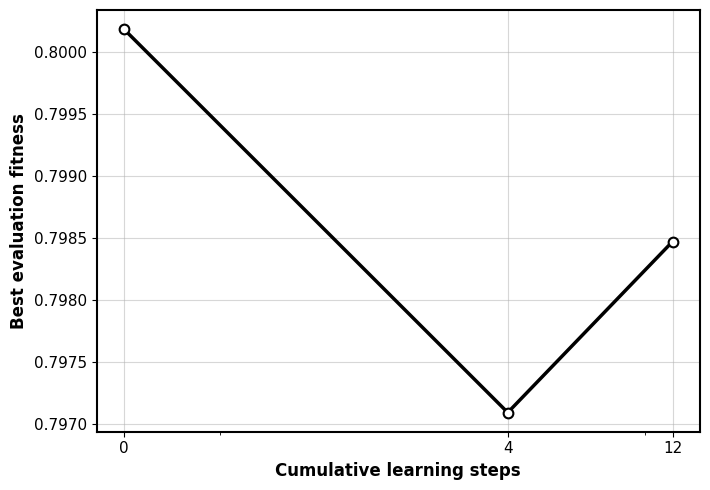

In [6]:
# Best-discovered evaluation fitness vs. experiential learning (average across K).
plot_pooled('evaluation_best_fitness', 'Best evaluation fitness',
            'Evaluation_best_fitness_across_learning_steps.png')

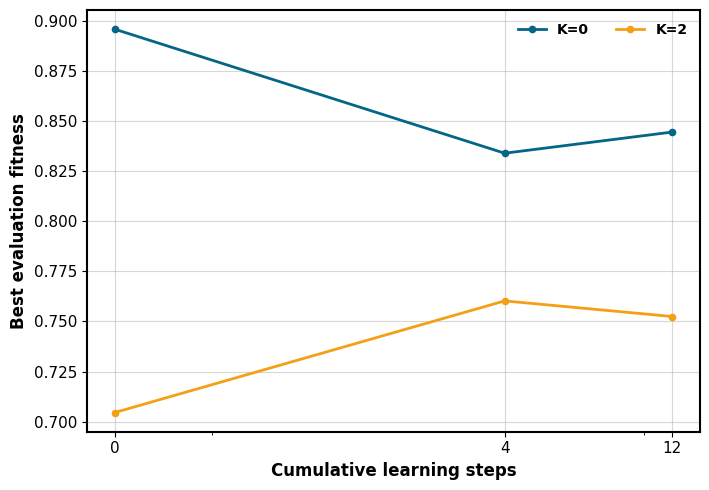

In [7]:
# Best-discovered evaluation fitness vs. experiential learning (by K).
plot_by_K('evaluation_best_fitness', 'Best evaluation fitness',
          'Evaluation_best_fitness_by_K_across_learning_steps.png')

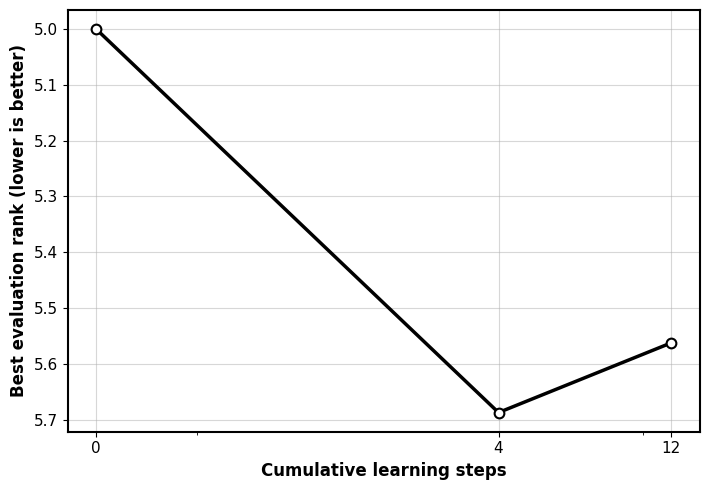

In [8]:
# Best-discovered solution rank (average across K; rank 1 is better).
plot_pooled('evaluation_best_rank', 'Best evaluation rank (lower is better)',
            'Evaluation_best_rank_across_learning_steps.png', invert=True)

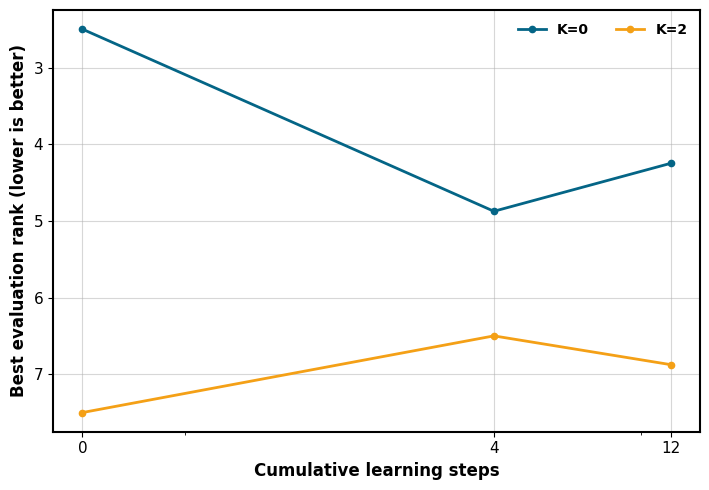

In [9]:
# Best-discovered solution rank (by K).
plot_by_K('evaluation_best_rank', 'Best evaluation rank (lower is better)',
          'Evaluation_best_rank_by_K_across_learning_steps.png', invert=True)

## 4. Internal knowledge: coverage and informativeness

Coverage is the share of the entire $2^N	imes N$ decision space with at least one update. Both measures are *descriptive knowledge-acquisition outcomes*, not direct measures of correctness.

- **State coverage:** fraction of states with at least one SARSA-updated action.
- **Action coverage:** fraction of all state–action pairs updated.
- **Informed percentage:** fraction of states with at least one nonzero Q-value (may differ from state coverage when an update remains zero).

In a large NK state space, coverage can remain low even after many learning steps.

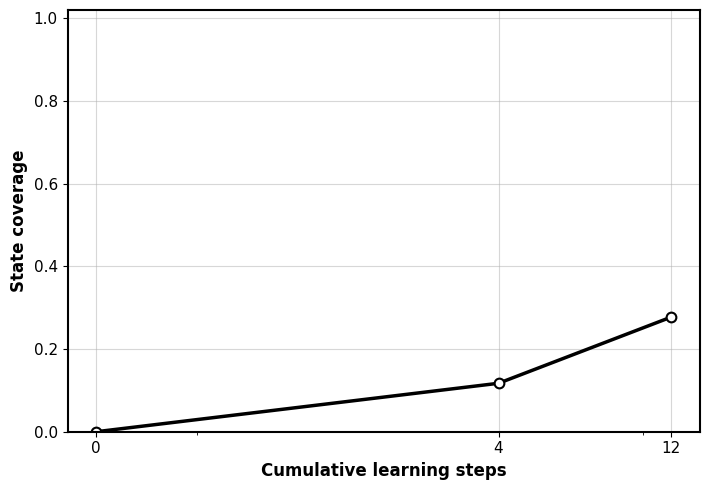

In [10]:
# Breadth of experiential learning (average across K).
plot_pooled('state_coverage', 'State coverage',
            'State_coverage_across_learning_steps.png', bounds=(0, 1.02))

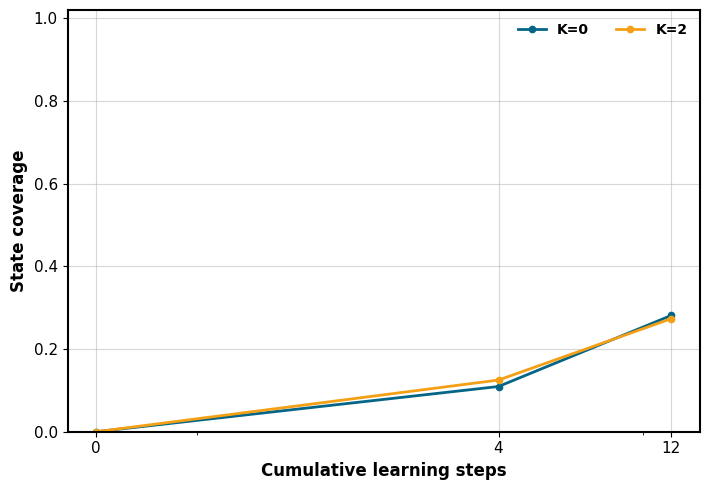

In [11]:
# Breadth of experiential learning (by K).
plot_by_K('state_coverage', 'State coverage',
          'State_coverage_by_K_across_learning_steps.png', bounds=(0, 1.02))

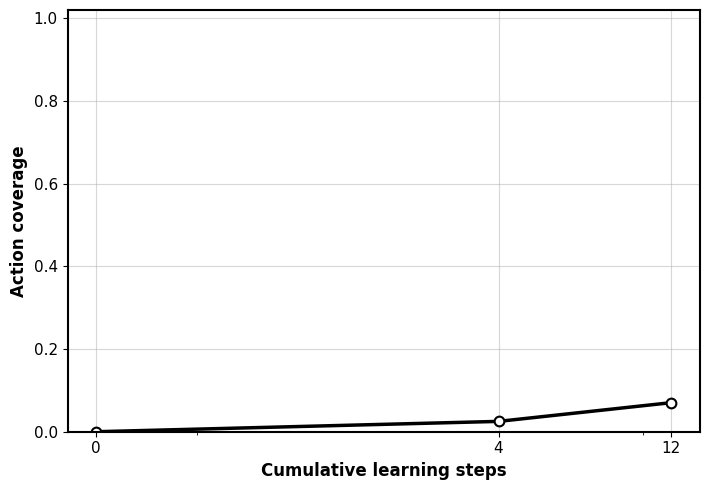

In [12]:
# Coverage of updated state-action pairs (average across K).
plot_pooled('action_coverage', 'Action coverage',
            'Action_coverage_across_learning_steps.png', bounds=(0, 1.02))

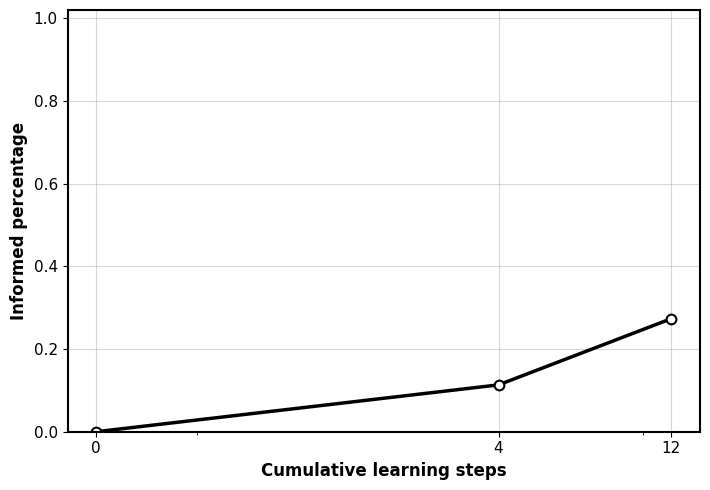

In [13]:
# Nonzero Q-value state coverage, retaining the original informativeness idea.
plot_pooled('informed_percentage', 'Informed percentage',
            'Informed_percentage_across_learning_steps.png', bounds=(0, 1.02))

## 5. Internal knowledge: Q-value accuracy

These measures are only available if `compute_accuracy=True` was used in the simulation. Missing (`NaN`) values are **not** treated as zero.

- **Overall Q accuracy:** one minus normalized RMSE of learned $Q(s,a)$ against the **exact on-policy** $Q^\pi(s,a)$ over all pairs.
- **Experienced Q accuracy:** the same comparison restricted to pairs with at least one update; this metric is **undefined** at zero learning steps.

**Caveat:** the reference $Q^\pi$ changes with the individual's current softmax policy, so accuracy is not evaluated against one invariant target. Experienced accuracy also has a changing denominator as more pairs are visited. These outcomes should be interpreted alongside coverage, not as independent ground-truth knowledge tests.

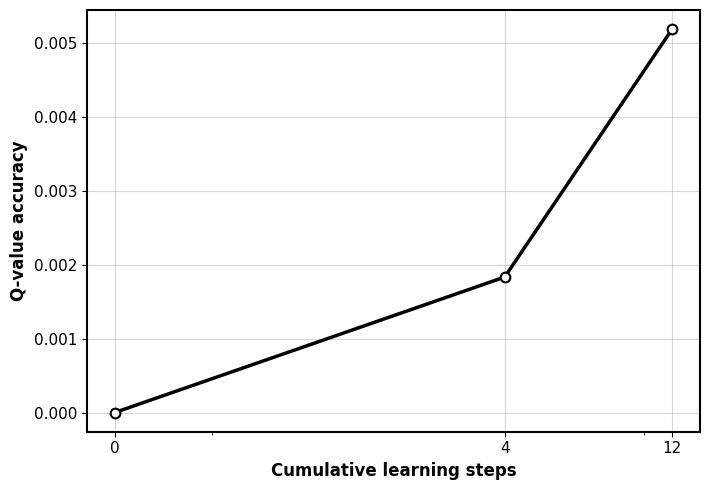

In [14]:
# Overall accuracy of the Q-table relative to the learner's current policy.
plot_pooled('q_accuracy', 'Q-value accuracy',
            'Q_accuracy_across_learning_steps.png')

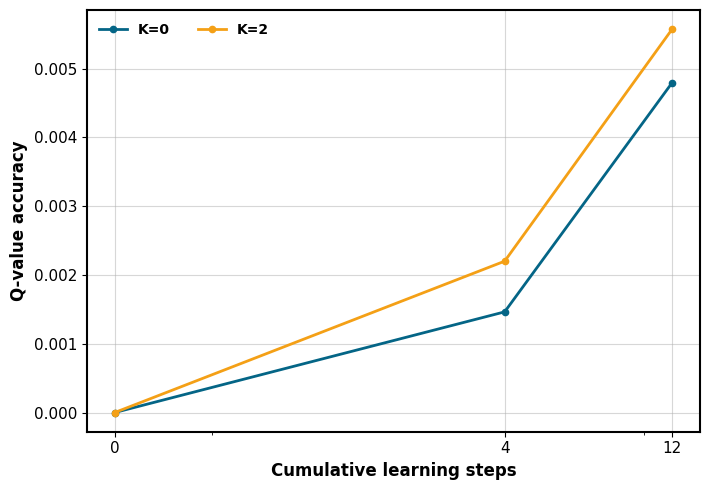

In [15]:
# Q-value accuracy separately by task interdependence.
plot_by_K('q_accuracy', 'Q-value accuracy',
          'Q_accuracy_by_K_across_learning_steps.png')

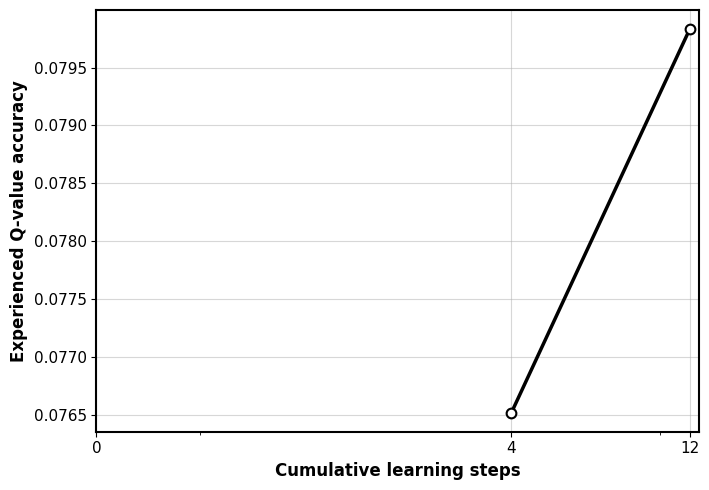

In [16]:
# Conditional Q-value accuracy among the state-action pairs actually learned.
plot_pooled('experienced_q_accuracy', 'Experienced Q-value accuracy',
            'Experienced_Q_accuracy_across_learning_steps.png')

## 6. Supplementary performance measures

Unlike the best-discovered metric, **final fitness** is the fitness at the final evaluation step; it can be lower if the individual moves away from a promising solution. **Evaluation fitness gain** equals best fitness minus starting fitness on the *same* evaluation trajectory. Results are descriptive across learning checkpoints and NK complexity.

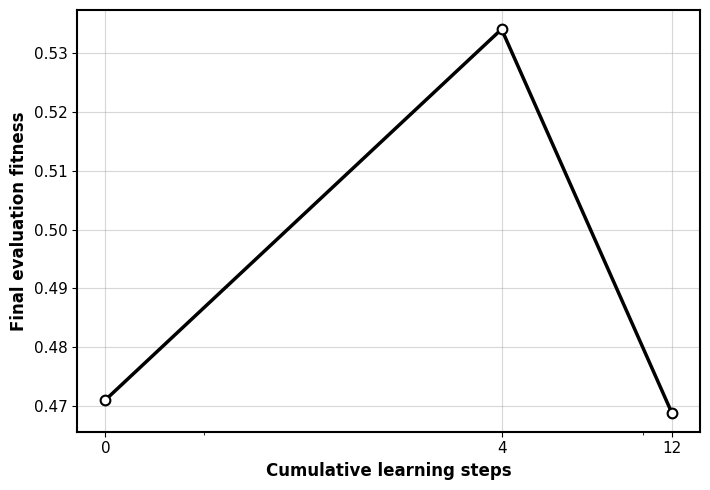

In [17]:
# Evaluation final-position fitness (average across K).
plot_pooled('evaluation_final_fitness', 'Final evaluation fitness',
            'Evaluation_final_fitness_across_learning_steps.png')

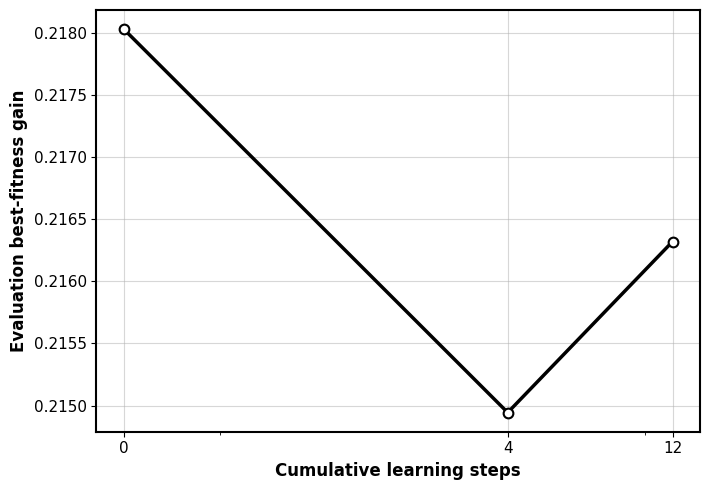

In [18]:
# Best-fitness gain relative to evaluation starts (average across K).
plot_pooled('evaluation_fitness_gain', 'Evaluation best-fitness gain',
            'Evaluation_fitness_gain_across_learning_steps.png')

## 7. Evaluation search trajectories

For each learning budget, the runner saves `organic_learning_steps_{steps}_evaluation_best_fitness_across_time_across_K`. This file is a **list ordered by `K_list`**, with one mean best-fitness trajectory per $K$ (including evaluation step 0). Each trajectory contains `search_iteration + 1` values.

The first figure compares learning budgets at a selected $K$; the second compares $K$ at a fixed learning budget. Trajectories already average across landscapes, individuals, and evaluation searches.

In [19]:
# =========================
# Load evaluation best-fitness trajectories
# =========================
trajectories = {K: {} for K in K_list}
missing_trajectories = []
for learning_steps in learning_steps_list:
    filename = (f'organic_learning_steps_{learning_steps}_'
                'evaluation_best_fitness_across_time_across_K')
    path = result_folder / filename
    if not path.is_file():
        missing_trajectories.append(filename)
        continue

    with open(path, 'rb') as infile:
        saved = np.asarray(pickle.load(infile), dtype=float)
    expected_shape = (len(K_list), search_iteration + 1)
    if saved.shape != expected_shape:
        raise ValueError(f'{filename}: expected shape {expected_shape}, '
                         f'got {saved.shape}')

    for i, K in enumerate(K_list):
        trajectories[K][learning_steps] = saved[i]

print('Loaded trajectory files:', len(learning_steps_list) - len(missing_trajectories),
      '/', len(learning_steps_list))
if missing_trajectories:
    print('Missing:', missing_trajectories)
    if strict_loading:
        raise FileNotFoundError('Missing evaluation trajectory pickle files.')

# The endpoint of mean best-fitness trajectories equals mean best fitness.
maximum_gap = 0.0
for K, by_budget in trajectories.items():
    for learning_steps, series in by_budget.items():
        scalar = data['evaluation_best_fitness'].loc[learning_steps, K]
        if np.isfinite(scalar):
            maximum_gap = max(maximum_gap, abs(float(series[-1]) - float(scalar)))
print('Max trajectory endpoint vs. summary fitness discrepancy:', maximum_gap)
if maximum_gap > 1e-8:
    warnings.warn('Evaluation trajectories do not match mean best-fitness values.')

Loaded trajectory files: 3 / 3
Max trajectory endpoint vs. summary fitness discrepancy: 0.0


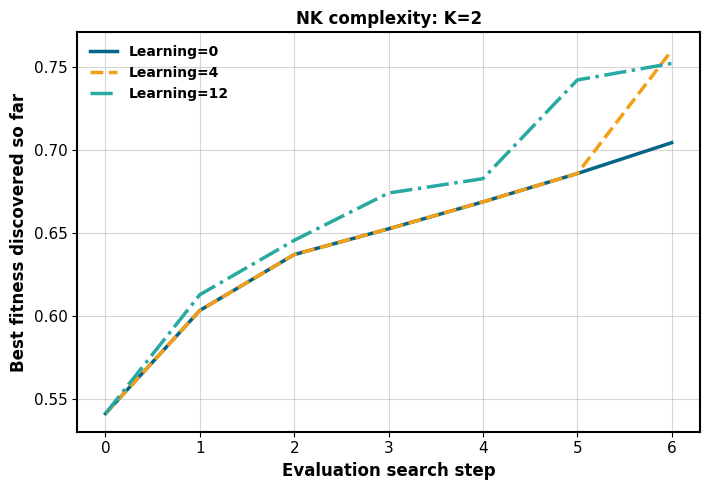

In [20]:
# Search process: three learning budgets on one selected NK complexity.
trajectory_K = K_list[len(K_list) // 2]  # Change to another observed K if desired.
selected_indices = [0, len(learning_steps_list) // 2, len(learning_steps_list) - 1]
trajectory_learning_steps = list(dict.fromkeys(
    learning_steps_list[index] for index in selected_indices))

if not trajectories.get(trajectory_K):
    print(f'No trajectory file for K={trajectory_K}.')
else:
    fig, ax = plt.subplots(figsize=(7.2, 5.0))
    format_axis(ax)
    for j, budget in enumerate(trajectory_learning_steps):
        if budget not in trajectories[trajectory_K]:
            print(f'No trajectory for K={trajectory_K}, learning_steps={budget}')
            continue
        series = trajectories[trajectory_K][budget]
        ax.plot(np.arange(len(series)), series, linewidth=2.5,
                linestyle=['-', '--', '-.'][j % 3],
                color=[morandi_blue, morandi_orange, morandi_green][j % 3],
                label=f'Learning={budget:,}')
    ax.set_xlabel('Evaluation search step', fontweight='bold', fontsize=12)
    ax.set_ylabel('Best fitness discovered so far', fontweight='bold', fontsize=12)
    ax.legend(frameon=False, prop={'weight': 'bold', 'size': 10})
    ax.set_title(f'NK complexity: K={trajectory_K}', fontweight='bold', fontsize=12)
    finish_figure(fig, f'Evaluation_trajectories_by_learning_budget_K_{trajectory_K}.png')

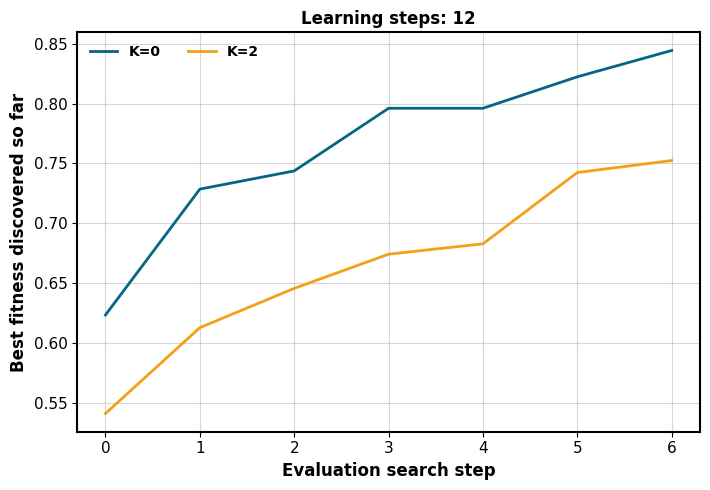

In [21]:
# Search process: compare K at the same (last) learning checkpoint.
trajectory_learning_budget = learning_steps_list[-1]
if not trajectories:
    print('No trajectory data available.')
else:
    fig, ax = plt.subplots(figsize=(7.2, 5.0))
    format_axis(ax)
    plotted = 0
    for j, K in enumerate(K_list):
        if K not in trajectories or trajectory_learning_budget not in trajectories[K]:
            continue
        series = trajectories[K][trajectory_learning_budget]
        ax.plot(np.arange(len(series)), series, linewidth=2.0,
                color=K_colors[j % len(K_colors)], label=f'K={K}')
        plotted += 1
    ax.set_xlabel('Evaluation search step', fontweight='bold', fontsize=12)
    ax.set_ylabel('Best fitness discovered so far', fontweight='bold', fontsize=12)
    ax.set_title(f'Learning steps: {trajectory_learning_budget:,}',
                 fontweight='bold', fontsize=12)
    if plotted:
        ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
        finish_figure(fig, f'Evaluation_trajectories_by_K_learning_{trajectory_learning_budget}.png')
    else:
        plt.close(fig)
        print('No matching checkpoint in any trajectory file.')

## 8. Learning × NK complexity: diagnostic heatmaps

Heatmaps display the underlying saved **$(K, \mathrm{learning\ steps})$ means** without pooling over complexity. These are diagnostics for heterogeneous effects, not statistical tests. Missing conditions remain blank.

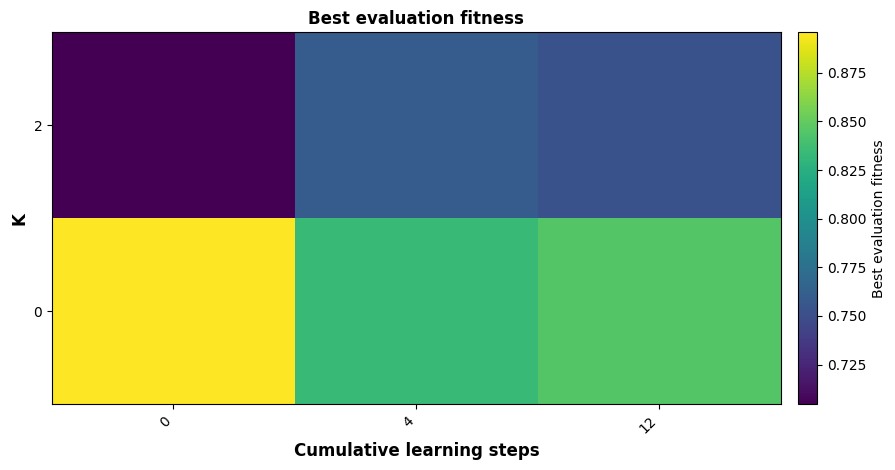

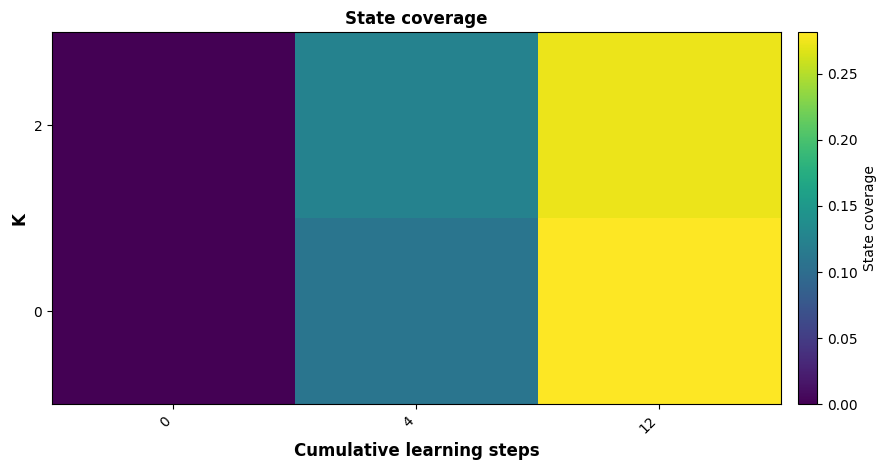

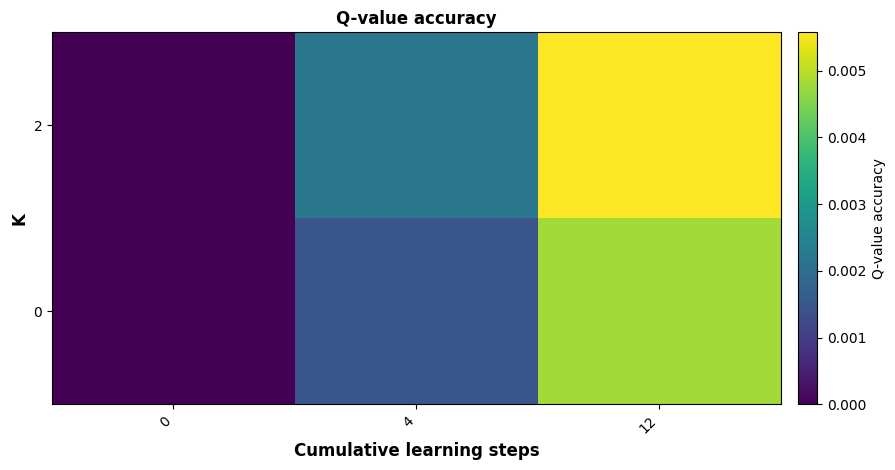

In [22]:
for measure, title, filename, cmap in [
    ('evaluation_best_fitness', 'Best evaluation fitness',
     'Evaluation_best_fitness_heatmap_learning_by_K.png', 'viridis'),
    ('state_coverage', 'State coverage',
     'State_coverage_heatmap_learning_by_K.png', 'viridis'),
    ('q_accuracy', 'Q-value accuracy',
     'Q_accuracy_heatmap_learning_by_K.png', 'viridis'),
]:
    if measure not in data or not np.isfinite(data[measure].to_numpy()).any():
        print(f'{measure} unavailable; heatmap skipped.')
        continue
    values = np.ma.masked_invalid(data[measure].T.to_numpy(dtype=float))
    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    image = ax.imshow(values, aspect='auto', interpolation='nearest',
                      cmap=cmap, origin='lower')
    ax.set_xticks(np.arange(len(learning_steps_list)))
    ax.set_xticklabels([f'{step:,}' for step in learning_steps_list],
                       rotation=45, ha='right')
    ax.set_yticks(np.arange(len(K_list)))
    ax.set_yticklabels(K_list)
    ax.set_xlabel('Cumulative learning steps', fontweight='bold', fontsize=12)
    ax.set_ylabel('K', fontweight='bold', fontsize=12)
    ax.set_title(title, fontweight='bold', fontsize=12)
    fig.colorbar(image, ax=ax, label=title, pad=0.02)
    finish_figure(fig, filename)

## 9. Interpretation

Use the performance curves to assess how additional **human experiential learning** changes subsequent fixed-budget solution discovery. Coverage and Q-value accuracy describe complementary dimensions of internal knowledge; plotted associations alone do **not** establish mediation.

**Design cautions:** Learning checkpoints reuse the same individual's Q-table and evaluation starting states. Outcomes have been averaged over independent landscapes and individual resets. The pickle files support descriptive figures, **not regression, uncertainty estimates, or statistical significance tests**. Equal-weighted averages across $K$ follow your previous evaluator's convention. With few smoke-test repetitions, the saved curves are only a functional preview.

In [23]:
# Compact report of available end-to-end comparisons (descriptive only).
comparison_measures = ['evaluation_best_fitness', 'evaluation_best_rank',
                       'state_coverage', 'action_coverage',
                       'q_accuracy', 'experienced_q_accuracy']
first_budget, last_budget = learning_steps_list[0], learning_steps_list[-1]
rows = []
for measure in comparison_measures:
    if measure not in data:
        continue
    pooled = data[measure].mean(axis=1, skipna=True)
    first, last = pooled.loc[first_budget], pooled.loc[last_budget]
    rows.append({'Measure': measure,
                 f'{first_budget:,} learning steps': first,
                 f'{last_budget:,} learning steps': last,
                 'Difference (last - first)': (last - first) if np.isfinite(first) and np.isfinite(last) else np.nan})
display(pd.DataFrame(rows).round(4))
print('All plots above summarize the loaded simulation outputs; no AI condition is included.')

,Measure,0 learning steps,12 learning steps,Difference (last - first)
0,evaluation_best_fitness,0.8002,0.7985,-0.0017
1,evaluation_best_rank,5.0000,5.5625,0.5625
2,state_coverage,0.0000,0.2773,0.2773
3,action_coverage,0.0000,0.0703,0.0703
4,q_accuracy,0.0000,0.0052,0.0052
5,experienced_q_accuracy,NaN,0.0798,NaN


All plots above summarize the loaded simulation outputs; no AI condition is included.
